# Analytical detectability and order effects

Study hyperedge-order sampling, signed aggregate corrections, and analytical diagrams. This notebook computes formulas and plots; it does not generate hypergraphs or run BP.
Run all cells from the repository root. All four figures are recomputed from the original analytical parameters, with outputs in `outputs/transition_detectivity/`. No external inputs, simulations, or pre-rendered figures are needed.


In [1]:
import csv
import json
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt

OUT = Path('outputs') / 'transition_detectivity'
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
def dot(x, y):
    return sum(a * b for a, b in zip(x, y))

def kl(p, q):
    return sum(a * math.log(a / b) for a, b in zip(p, q))

def evaluate(orders, probabilities, incidence=1.0, signal=1.0):
    """Reproduce the core analytical calculations from analytic_physics.py."""
    support = [(d, p) for d, p in zip(orders, probabilities) if p > 0]
    assert support and all(d >= 2 and int(d) == d for d, _ in support)
    orders, p = map(list, zip(*support))
    assert math.isclose(sum(p), 1, abs_tol=1e-12)
    assert incidence > 0 and signal != 0

    w = [d * (d - 1) for d in orders]
    chi = [2 / value for value in w]
    logchi = [math.log(value) for value in chi]
    F, E_w = dot(p, orders), dot(p, w)
    P_I = [mass * d / F for mass, d in zip(p, orders)]
    P_B = [mass * value / E_w for mass, value in zip(p, w)]
    E_chi2 = dot(P_B, [value**2 for value in chi])
    P_V = [mass * value**2 / E_chi2 for mass, value in zip(P_B, chi)]

    branching = incidence * E_w / F
    G = branching * signal**2 * E_chi2
    G_aggregate = incidence * (F - 1) * signal**2 * math.exp(2 * dot(p, logchi))
    delta_B = math.log(branching / (incidence * (F - 1)))
    Delta_J = math.log(E_chi2) - 2 * dot(P_B, logchi)
    Delta_W = 2 * (dot(P_B, logchi) - dot(p, logchi))
    log_ratio = math.log(G / G_aggregate)
    error_budget = delta_B + Delta_J + abs(Delta_W)

    # Original identity and numerical consistency checks.
    assert abs(log_ratio - (delta_B + Delta_J + Delta_W)) < 2e-12
    assert abs(Delta_J - kl(P_B, P_V)) < 2e-12
    assert abs(Delta_W + 2 * (kl(P_B, p) + kl(p, P_B))) < 2e-12
    assert delta_B >= -1e-12 and Delta_J >= -1e-12 and Delta_W <= 1e-12
    assert abs(log_ratio) <= error_budget + 1e-12
    assert math.isclose(G, 2 * incidence * signal**2 / F * dot(p, chi), rel_tol=1e-12)
    P_V_edge = [mass * value / dot(p, chi) for mass, value in zip(p, chi)]
    assert max(abs(a - b) for a, b in zip(P_V, P_V_edge)) < 1e-12
    if abs(math.log(G_aggregate)) > error_budget + 1e-12:
        assert (G > 1) == (G_aggregate > 1)

    return dict(orders=orders, P_E=p, P_I=P_I, P_B=P_B, P_V=P_V,
                mean_order=F, mean_branching=branching, incidence=incidence,
                signal=signal, G=G, G_aggregate=G_aggregate,
                delta_B=delta_B, Delta_J=Delta_J, Delta_W=Delta_W,
                log_ratio=log_ratio, error_budget=error_budget)

def two_layer(d):
    # Set c0=10, beta_2=beta_d=1, and lambda=1.
    mass = [1 / 2, 1 / (d * (d - 1))]
    p = [value / sum(mass) for value in mass]
    return evaluate([2, d], p, incidence=10 * (1 + 1 / (d - 1)))

In [3]:
def checks():
    for d in (2, 3, 10, 50):
        row = evaluate([d], [1])
        assert max(abs(row[key]) for key in ('delta_B', 'Delta_J', 'Delta_W', 'log_ratio')) < 1e-12
    rng = random.Random(20260918)
    for _ in range(1000):
        orders = sorted(rng.sample(range(2, 101), rng.randrange(2, 10)))
        weights = [math.exp(rng.uniform(-12, 4)) for _ in orders]
        evaluate(orders, [value / sum(weights) for value in weights],
                 incidence=math.exp(rng.uniform(-2, 12)), signal=rng.uniform(.02, 1))
    assert two_layer(3)['log_ratio'] > 0
    assert two_layer(20)['log_ratio'] < 0
    r50 = two_layer(50)
    assert abs(r50['P_E'][1] - 1 / 1226) < 1e-15
    assert abs(r50['P_B'][1] - .5) < 1e-15
    assert abs(r50['P_V'][1] - 1 / 1500626) < 1e-15
    return dict(random_distributions=1000, single_order_cases=4,
                signed_decomposition=True, kl_identities=True,
                independent_edge_moment_check=True,
                opposite_error_signs=True, stability_margin_check=True)

verified = checks()
rows = [two_layer(d) for d in range(3, 61)]
values = dict(description='Analytical evaluations only; no BP measurements.',
              examples={str(d): two_layer(d) for d in (3, 20, 50)},
              checks=verified)

(OUT / 'analytic_physics_values.json').write_text(json.dumps(values, indent=2) + '\n')
with (OUT / 'analytic_physics_orders.csv').open('w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['d', 'P_E_high', 'P_I_high', 'P_B_high', 'P_V_high',
                     'G_over_lambda_squared', 'G_aggregate_over_lambda_squared',
                     'delta_B', 'Delta_J', 'Delta_W', 'log_ratio'])
    for row in rows:
        writer.writerow([row['orders'][1]] + [row[key][1] for key in ('P_E', 'P_I', 'P_B', 'P_V')]
                        + [row[key] for key in ('G', 'G_aggregate', 'delta_B', 'Delta_J', 'Delta_W', 'log_ratio')])

print(json.dumps(values['examples'], indent=2))

{
  "3": {
    "orders": [
      2,
      3
    ],
    "P_E": [
      0.75,
      0.25
    ],
    "P_I": [
      0.6666666666666666,
      0.3333333333333333
    ],
    "P_B": [
      0.5,
      0.5
    ],
    "P_V": [
      0.8999999999999999,
      0.09999999999999999
    ],
    "mean_order": 2.25,
    "mean_branching": 20.0,
    "incidence": 15.0,
    "signal": 1.0,
    "G": 11.11111111111111,
    "G_aggregate": 10.825317547305483,
    "delta_B": 0.06453852113757116,
    "Delta_J": 0.5108256237659908,
    "Delta_W": -0.5493061443340549,
    "log_ratio": 0.026058000569506905,
    "error_budget": 1.124670289237617
  },
  "20": {
    "orders": [
      2,
      20
    ],
    "P_E": [
      0.9947643979057591,
      0.005235602094240837
    ],
    "P_I": [
      0.95,
      0.049999999999999996
    ],
    "P_B": [
      0.5,
      0.5
    ],
    "P_V": [
      0.9999722999362898,
      2.770006371014653e-05
    ],
    "mean_order": 2.094240837696335,
    "mean_branching": 19.999999999999

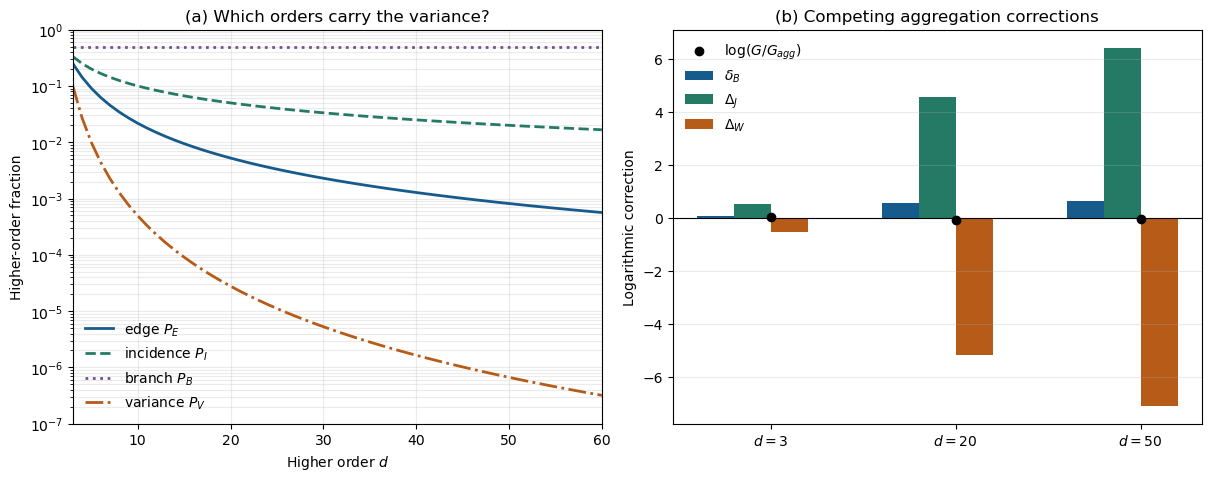

输出文件夹：D:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\transition_detectivity


In [4]:
# Notebook plots of the same data as the original ReportLab figure.
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4.7), constrained_layout=True)
d = [row['orders'][1] for row in rows]
styles = {'P_E': ('#165B8C', '-', 'edge $P_E$'),
          'P_I': ('#247A64', '--', 'incidence $P_I$'),
          'P_B': ('#77508E', ':', 'branch $P_B$'),
          'P_V': ('#B65B18', '-.', 'variance $P_V$')}
for key, (color, linestyle, label) in styles.items():
    ax0.semilogy(d, [row[key][1] for row in rows], color=color, ls=linestyle, lw=2, label=label)
ax0.set(xlabel='Higher order $d$', ylabel='Higher-order fraction',
        title='(a) Which orders carry the variance?', xlim=(3, 60), ylim=(1e-7, 1))
ax0.grid(alpha=.25, which='both'); ax0.legend(frameon=False)

chosen = [two_layer(d0) for d0 in (3, 20, 50)]
x = range(3)
width = .2
for offset, key, color, label in [(-1.5, 'delta_B', '#165B8C', r'$\delta_B$'),
                                  (-.5, 'Delta_J', '#247A64', r'$\Delta_J$'),
                                  (.5, 'Delta_W', '#B65B18', r'$\Delta_W$')]:
    ax1.bar([i + offset * width for i in x], [row[key] for row in chosen],
            width, color=color, label=label)
ax1.scatter(x, [row['log_ratio'] for row in chosen], color='black', zorder=3, label=r'$\log(G/G_{agg})$')
ax1.axhline(0, color='black', lw=.8)
ax1.set(xticks=list(x), xticklabels=['$d=3$', '$d=20$', '$d=50$'],
        ylabel='Logarithmic correction', title='(b) Competing aggregation corrections')
ax1.grid(axis='y', alpha=.25); ax1.legend(frameon=False)
fig.savefig(OUT / 'aggregation_physical_mechanism.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'输出文件夹：{OUT.resolve()}')

## Order effects under a shared affinity matrix: three standalone figures

Plot the three panels discussed above as separate analytical figures, without generating hypergraphs or running BP. Retain orders $2,\ldots,D$, sharing the complete affinity matrix across layers, with $\beta_d=1$, common layer mean $c$, and fixed community signal $\lambda$. The fixed quantity is each layer's $c$; total incidence $\bar k_{\mathrm h}=cH_{D-1}$ increases with $D$.

$$
S_D=\sum_{d=2}^D\frac{4}{d^2(d-1)^2},\qquad
G=c\lambda^2S_D,\qquad
\Phi_D=\frac{K-1}{K\sqrt c}\gamma_D,\qquad
\gamma_D=S_D^{-1/2}.
$$

Here $\rho_{\mathrm{in}}=c_{\mathrm{in}}/(Kc)$; the uninformative fixed point is locally unstable when $|\rho_{\mathrm{in}}-1/K|>\Phi_D$.
Panel (a) shows the $D=2$ boundary; shading indicates local instability, rather than the information-theoretic detection region for all algorithms.
In panel (b), $\gamma_1=\sqrt{(D-1)/S_D}$ represents the threshold cost of weaker mean branch response, while $\gamma_2=1/\sqrt{D-1}$ represents the reduction from more branches; their product is $\gamma_D$. These factors decompose this section's order-resolved second-moment formula and do not correspond term by term to the literature's geometric-mean decomposition.
Panel (c) plots $100(\Phi_D/\Phi_2-1)=100(\gamma_D-1)$, independent of $c$. It shows relative changes in boundary separation, rather than changes in accuracy or AUC.

Run the parameter/calculation cell first, then any of the three independent plot cells. Parameters and output controls are in the calculation cell; panel (b) includes the gamma-decomposition inset.
Save figures as `order_resolved_pairwise_boundary`, `order_resolved_gamma_decomposition`, and `order_resolved_relative_gap_change` (PNG and SVG), plus a shared CSV data table.

In [5]:
# Analytical parameters and data, independent of evaluate() and rows above.
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

OD_D_MAX = 40
OD_K_MAX = 20
OD_C_VALUES = (10.0, 30.0)
OD_C_HEATMAP = (2.0, 40.0)
OD_SAVE = True
OD_OUT = Path("outputs") / "transition_detectivity"

if int(OD_D_MAX) != OD_D_MAX or OD_D_MAX < 2:
    raise ValueError("OD_D_MAX must be an integer >= 2.")
if int(OD_K_MAX) != OD_K_MAX or OD_K_MAX < 2:
    raise ValueError("OD_K_MAX must be an integer >= 2.")
if len(OD_C_VALUES) != 2 or not all(np.isfinite(c) and c > 0 for c in OD_C_VALUES):
    raise ValueError("OD_C_VALUES must contain two positive finite layer means.")
if not 0 < OD_C_HEATMAP[0] < OD_C_HEATMAP[1] < np.inf:
    raise ValueError("OD_C_HEATMAP must contain increasing positive finite bounds.")

od_orders = np.arange(2, int(OD_D_MAX) + 1)
od_chi = 2.0 / (od_orders * (od_orders - 1))
od_S = np.cumsum(od_chi**2)
od_gamma = od_S**-0.5
od_gamma1 = np.sqrt((od_orders - 1) / od_S)
od_gamma2 = 1.0 / np.sqrt(od_orders - 1)
od_gamma_inf = (4.0 * np.pi**2 / 3.0 - 12.0)**-0.5
od_delta_percent = 100.0 * (od_gamma - 1.0)

print("Analytical local-stability predictions; no BP simulations.")
print("  D       S_D       gamma_D     gap change [%]")
for od_d in sorted({2, 3, 5, 10, 30, int(OD_D_MAX)}):
    if od_d <= OD_D_MAX:
        od_i = od_d - 2
        print(f"{od_d:3d}  {od_S[od_i]:10.7f}  {od_gamma[od_i]:10.7f}  {od_delta_percent[od_i]:12.6f}")
print(f"gamma infinity = {od_gamma_inf:.9f}")

OD_STYLE = {
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "mathtext.fontset": "dejavusans",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.facecolor": "white",
}

# Save the numerical table shared by all three figures once here.
if OD_SAVE:
    OD_OUT.mkdir(parents=True, exist_ok=True)
    np.savetxt(
        OD_OUT / "order_resolved_counterpart_values.csv",
        np.column_stack([od_orders, od_S, od_gamma, od_gamma1, od_gamma2, od_delta_percent]),
        delimiter=",",
        header="D,S_D,gamma_D,gamma1,gamma2,relative_gap_change_percent",
        comments="",
    )


Analytical local-stability predictions; no BP simulations.
  D       S_D       gamma_D     gap change [%]
  2   1.0000000   1.0000000      0.000000
  3   1.1111111   0.9486833     -5.131670
  5   1.1488889   0.9329556     -6.704438
 10   1.1581418   0.9292212     -7.077877
 30   1.1594232   0.9287076     -7.129237
 40   1.1594517   0.9286962     -7.130380
gamma infinity = 0.928687857


Saved: D:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\transition_detectivity\order_resolved_pairwise_boundary.png


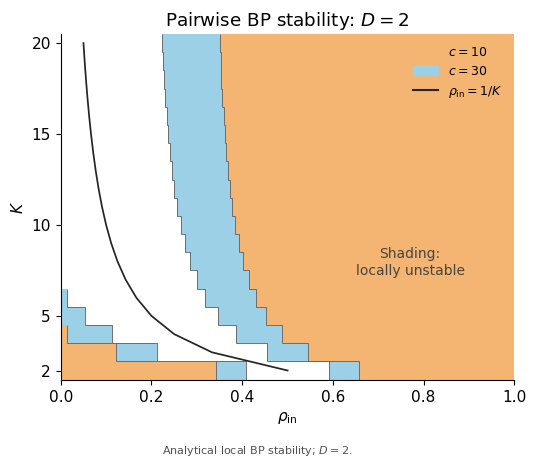

In [6]:
# Run the parameter/calculation cell first; this plot is independent of the other plot cells.
with plt.rc_context(OD_STYLE):
    # (a) D=2, Phi_2=(K-1)/(K*sqrt(c))。
    od_fig, od_ax = plt.subplots(figsize=(5.6, 4.8))
    od_K = np.arange(2, int(OD_K_MAX) + 1, dtype=float)
    od_K_edges = np.arange(2, int(OD_K_MAX) + 2, dtype=float) - 0.5
    od_colors = ("#f5b572", "#9bd0e7")
    od_layers = list(zip(OD_C_VALUES, od_colors))
    for od_c, od_color in sorted(od_layers, key=lambda item: item[0], reverse=True):
        od_phi = (od_K - 1) / (od_K * np.sqrt(od_c))
        od_lower = 1.0 / od_K - od_phi
        od_upper = 1.0 / od_K + od_phi
        # Clip to rho's physical domain; omit boundaries outside it.
        od_ax.stairs(np.minimum(od_upper, 1), od_K_edges, orientation="horizontal",
                     baseline=1, fill=True, color=od_color, linewidth=0)
        od_ax.stairs(np.maximum(od_lower, 0), od_K_edges, orientation="horizontal",
                     baseline=0, fill=True, color=od_color, linewidth=0)
        od_ax.stairs(np.where(od_upper <= 1, od_upper, np.nan), od_K_edges,
                     orientation="horizontal", baseline=None, color="#666666", lw=0.65)
        od_ax.stairs(np.where(od_lower >= 0, od_lower, np.nan), od_K_edges,
                     orientation="horizontal", baseline=None, color="#666666", lw=0.65)
    od_ax.plot(1.0 / od_K, od_K, color="#252525", lw=1.25)
    od_ax.set(
        xlim=(0, 1), ylim=(1.5, OD_K_MAX + 0.5),
        xlabel=r"$\rho_{\rm in}$", ylabel=r"$K$",
        title="Pairwise BP stability: $D=2$",
    )
    od_ax.set_yticks(sorted({2, *range(5, int(OD_K_MAX) + 1, 5)}))
    od_ax.legend(handles=[
        *[Patch(color=color, label=f"$c={c:g}$") for c, color in od_layers],
        Line2D([0], [0], color="#252525", label=r"$\rho_{\rm in}=1/K$"),
    ], loc="upper right", frameon=False, fontsize=9)
    od_ax.text(0.77, 0.34, "Shading:\nlocally unstable", transform=od_ax.transAxes,
               ha="center", va="center", fontsize=10, color="#454545")


    od_fig.subplots_adjust(left=0.15, right=0.96, bottom=0.18, top=0.90)
    od_fig.text(0.5, 0.025, "Analytical local BP stability; $D=2$.", ha="center", fontsize=8, color="#505050")
    if OD_SAVE:
        OD_OUT.mkdir(parents=True, exist_ok=True)
        od_fig.savefig(OD_OUT / "order_resolved_pairwise_boundary.png", dpi=200)
        od_fig.savefig(OD_OUT / "order_resolved_pairwise_boundary.svg")
        print(f"Saved: {(OD_OUT / 'order_resolved_pairwise_boundary.png').resolve()}")
    plt.show()
    plt.close(od_fig)


Saved: D:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\transition_detectivity\order_resolved_gamma_decomposition.png


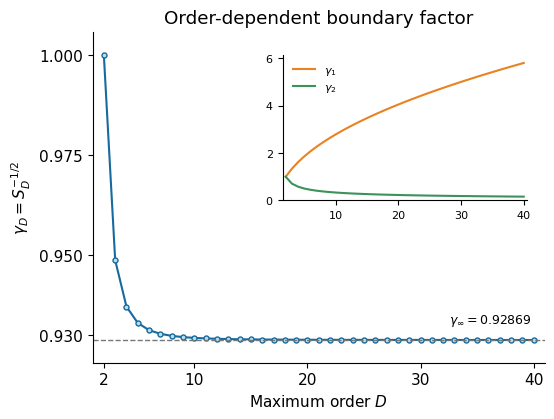

In [7]:
# Run the parameter/calculation cell first; this plot is independent of the other plot cells.
with plt.rc_context(OD_STYLE):
    # (b) With equal layer means, gamma_D approaches a nonzero limit rapidly.
    od_fig, od_ax = plt.subplots(figsize=(5.8, 4.8))
    od_ax.plot(od_orders, od_gamma, "o-", ms=3.6, lw=1.5,
               color="#166a9d", mfc="#b8def1")
    od_ax.axhline(od_gamma_inf, color="#777777", ls="--", lw=1)
    od_ax.text(0.97, 0.105, rf"$\gamma_\infty={od_gamma_inf:.5f}$",
               transform=od_ax.transAxes, ha="right", va="bottom", fontsize=9)
    od_ax.set(
        xlim=(1, OD_D_MAX + 1), ylim=(0.923, 1.006),
        xlabel=r"Maximum order $D$", ylabel=r"$\gamma_D=S_D^{-1/2}$",
        title="Order-dependent boundary factor",
    )
    od_ticks = sorted({2, *range(10, int(OD_D_MAX) + 1, 10)})
    od_ax.set_xticks(od_ticks)
    od_ax.set_yticks([0.93, 0.95, 0.975, 1])
    od_inset = od_ax.inset_axes([0.42, 0.49, 0.54, 0.44])
    od_inset.plot(od_orders, od_gamma1, color="#e98221", label=r"$\gamma_1$")
    od_inset.plot(od_orders, od_gamma2, color="#3b925a", label=r"$\gamma_2$")
    od_inset.set(xlim=(1.5, OD_D_MAX + 0.5), ylim=(0, max(1.2, 1.06 * od_gamma1.max())))
    od_inset.tick_params(labelsize=8)
    od_inset.legend(loc="upper left", fontsize=8, frameon=False)


    od_fig.subplots_adjust(left=0.18, right=0.96, bottom=0.21, top=0.90)
    # od_fig.text(0.5, 0.025, 'Fixed layer mean $c$; $\\beta_d=1$; common signal.\nAnalytical local-stability predictions.', ha="center", fontsize=8, color="#505050")
    if OD_SAVE:
        OD_OUT.mkdir(parents=True, exist_ok=True)
        od_fig.savefig(OD_OUT / "order_resolved_gamma_decomposition.png", dpi=200)
        od_fig.savefig(OD_OUT / "order_resolved_gamma_decomposition.svg")
        print(f"Saved: {(OD_OUT / 'order_resolved_gamma_decomposition.png').resolve()}")
    plt.show()
    plt.close(od_fig)


Saved: D:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\transition_detectivity\order_resolved_relative_gap_change.png


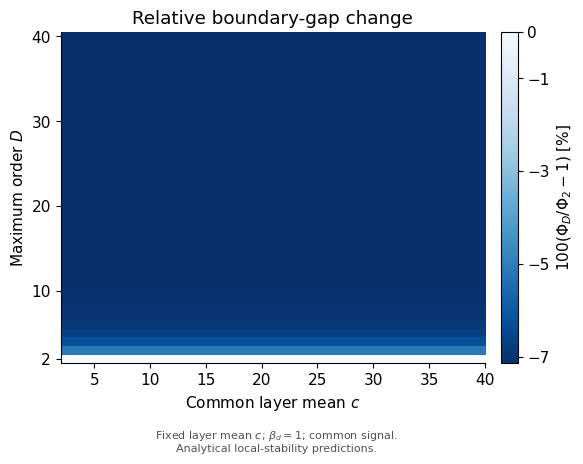

In [8]:
# Run the parameter/calculation cell first; this plot is independent of the other plot cells.
with plt.rc_context(OD_STYLE):
    # (c) c and K cancel from the relative change, so every row has the same colors.
    od_fig, od_ax = plt.subplots(figsize=(6.0, 4.8))
    od_c_grid = np.linspace(*OD_C_HEATMAP, 160)
    od_heatmap = np.repeat(od_delta_percent[:, None], len(od_c_grid), axis=1)
    od_image = od_ax.imshow(
        od_heatmap, origin="lower", aspect="auto", interpolation="nearest",
        extent=[*OD_C_HEATMAP, 1.5, OD_D_MAX + 0.5],
        cmap="Blues_r", vmin=-7.14, vmax=0,
    )
    od_ax.set(
        xlabel=r"Common layer mean $c$", ylabel=r"Maximum order $D$",
        title="Relative boundary-gap change",
        ylim=(1.5, OD_D_MAX + 0.5), yticks=sorted({2, *range(10, int(OD_D_MAX) + 1, 10)}),
    )
    od_colorbar = od_fig.colorbar(od_image, ax=od_ax, pad=0.035, fraction=0.047)
    od_colorbar.set_label(r"$100(\Phi_D/\Phi_2-1)$ [%]")
    od_colorbar.set_ticks([-7, -5, -3, -1, 0])


    od_fig.subplots_adjust(left=0.14, right=0.91, bottom=0.21, top=0.90)
    od_fig.text(0.5, 0.025, 'Fixed layer mean $c$; $\\beta_d=1$; common signal.\nAnalytical local-stability predictions.', ha="center", fontsize=8, color="#505050")
    if OD_SAVE:
        OD_OUT.mkdir(parents=True, exist_ok=True)
        od_fig.savefig(OD_OUT / "order_resolved_relative_gap_change.png", dpi=200)
        od_fig.savefig(OD_OUT / "order_resolved_relative_gap_change.svg")
        print(f"Saved: {(OD_OUT / 'order_resolved_relative_gap_change.png').resolve()}")
    plt.show()
    plt.close(od_fig)
